# 06 点赞系统：通用服务、Redis 去重与批量消息同步


## 本章范围与资料来源

第 05 章已经能展示回答和评论，但“这条回答有多少赞、我是否赞过”还需要独立的数据。本章完成点赞与取消、批量查询当前用户的点赞状态、通知业务方更新点赞数，再用 Redis 和定时批处理减少数据库压力。

| 来源 | 本章采用的内容 |
| --- | --- |
| [网盘分享](https://pan.baidu.com/s/1dcVvDI-sWN68Xzcsz1LSAQ?pwd=w7bj)，提取码 `w7bj` | `day06-点赞系统/讲义/day06-点赞系统.pptx`，共 33 页。需求、表结构、两个接口、消息路由、Set/ZSet、定时同步和 Pipeline |
| `day06-点赞系统/作业.txt` | 把业务类型、定时任务批处理数量、Redis key 前缀放到 Nacos，实现动态获取 |
| `day06-点赞系统/资料` | 确认包含 `LikeRecordFormDTO.java`、`LikedTimesDTO.java`、`tj_remark.sql`。Java 预览出现签名错误，未取得附件全文 |

阅读日期：2026-10-09。官方知识库入口能打开 day01，但本次未取得 day06 在线讲义全文。因此，**课件方案**以已读 PPT 和作业为依据；**整理示例**把 PPT 的流程写成便于阅读的代码；**补充 / 改进示例**解释并发、故障和通用化边界。示例类名、配置项和 Redis 键名均不宣称是附件源码。

学习顺序：服务职责 → 关系模型 → 数据库版接口 → MQ 与问答联动 → Redis 改造 → Pipeline → 定时同步 → 一致性 → Nacos 作业。

所有单元都是 Markdown。Java、SQL、Redis、Lua、YAML 代码用于阅读，不能在 Python 内核直接运行。本章整理笔记，不执行课程服务、数据库脚本或中间件操作。


## 点赞服务的职责与业务解耦

回答、学习笔记都能被点赞。如果在每个业务服务里重复实现“防重复、取消、计数”，后续修改规则就要改多份代码。课件把点赞抽成独立服务，要求通用、独立、能承受并发，并避免重复点赞。

**通用点赞服务只需要知道“谁赞了哪个目标”。** 目标的内容和展示规则仍由业务服务维护。`bizId` 是目标业务 ID，`bizType` 是类型，例如问答 `qa`、笔记 `note`。

| 模块 | 负责保存或处理 | 与另一方的协作 |
| --- | --- | --- |
| 点赞服务 | 用户与目标的点赞关系、去重、当前总数、状态查询 | 发 MQ 消息通知业务方 |
| 学习服务的问答业务 | 回答内容、匿名/隐藏规则、回答上的 `likedTimes` | 批量查当前用户状态，消费点赞数变更 |
| 笔记业务 | 笔记内容和自己的点赞数 | 订阅对应类型的消息 |

同步 HTTP 调用会让点赞请求依赖业务服务是否在线。课件选择 MQ，让点赞服务发布事件，由各业务服务分别消费。

> “独立”仍需要明确接口和消息契约。它不意味着点赞服务能跳过登录校验，也不意味着所有提交的目标 ID 都天然合法。

**实践场景**：增加课程评价点赞时，先约定新类型和消费规则，再接入公共点赞接口；调整问答展示时，只修改问答业务，不让点赞服务读取回答表。


## 点赞关系、个人状态与总数

页面同时显示图标是否点亮和点赞数量，但这两个信息回答的问题不同。

| 信息 | 含义 | 示例 | 数据来源 |
| --- | --- | --- | --- |
| 点赞关系 | 用户 U 是否赞了目标 B | 用户 7 赞了回答 1001 | 数据库记录或 Redis Set 成员 |
| 当前用户状态 `liked` | 当前访问者是否存在这条关系 | 用户 7 为 true，用户 8 为 false | 对当前用户批量查询 |
| 点赞数 `likedTimes` | 目标有多少个不同用户点赞 | 回答 1001 有 20 个赞 | 关系计数及业务表的同步副本 |

**个人状态不能由总数推断。** 20 个赞不代表当前用户赞过。总数同样不能只存在用户界面上，它应能由关系集合重新计算。

假设用户 7 的状态从未点赞变成已点赞，总数从 20 变成 21。再次请求点赞时，关系不再增加，总数仍是 21。取消后关系删除，总数回到 20。

课件优化后，个人状态从 Redis 实时读取，业务列表中的总数通过定时 MQ 同步。因此图标已经点亮、列表数量稍后才增加，是这种异步模型允许的短暂现象。


## 提交目标状态与幂等性

网络重试和用户连点会重复发送请求。如果接口仅表示“切换一下”，同一个请求重试两次就会恢复原状态。

课件接口提交 `liked`：`true` 表示希望已点赞，`false` 表示希望未点赞。这种**目标状态**便于实现幂等，即重复执行同一请求不继续改变最终状态。

| 已存状态 | 请求 `liked` | 关系操作 | 是否需要同步总数 |
| --- | --- | --- | --- |
| 未点赞 | true | 新增关系 | 是 |
| 已点赞 | true | 无变化 | 否 |
| 已点赞 | false | 删除关系 | 是 |
| 未点赞 | false | 无变化 | 否 |

整理示例：

```json
{"bizId":1001,"bizType":"qa","liked":true}
```

> 幂等解决重复请求的影响。用户先点赞、再取消，如果两个不同请求乱序到达，普通接口仍可能以最后到达的请求为准。

**补充**：界面在一次操作完成前限制重复提交；若产品要求严格保留用户操作顺序，需要请求序号或按用户与目标串行处理。不能把点赞、取消两个不同状态的请求都当作“重复消息”丢弃。


## 业务 ID、业务类型与唯一关系

通用服务会接入不同业务，而不同表里的数值 ID 可能相同。模型必须明确一个目标如何唯一确定。

课件点赞表的唯一键是 `(biz_id, user_id)`，状态查询接口只传 `bizIds`，Redis 关系集合也以 `bizId` 为核心。这要求接入方保证：**不同类型的目标不会共用同一个业务 ID。** 项目采用分布式 ID，并不自动证明每个接入业务都满足该条件，接入时仍需核对。

| ID 规则 | 唯一关系 | 查询与缓存要求 |
| --- | --- | --- |
| 所有点赞目标全局唯一 | `(bizId,userId)` | 可以只用 bizId 查状态，bizType 用于路由 |
| 不同业务允许相同 ID | `(bizType,bizId,userId)` | 接口、唯一索引、Redis key 都必须包含类型 |

**正例**：回答 ID 1001、笔记 ID 2001，二者全局不重复。用户可以分别点赞。

**反例**：回答和笔记都叫 1001，关系仅用 `bizId=1001`。给回答点赞后，笔记也显示已点赞，甚至取消笔记会移除回答的赞。

**补充 / 改进示例**：如果不能保证全局唯一，可以新增按类型查询的接口版本，而不是只改数据库索引。契约的一端改了，另一端仍只传 ID，混淆仍会发生。


## 点赞记录表与唯一索引

只保存总数无法判断用户是否重复点赞。数据库版先保存每一条用户与目标的关系，再统计数量。

课件第 10 页表结构，去掉示例自增起点后的整理：

```sql
CREATE TABLE IF NOT EXISTS liked_record (
    id BIGINT NOT NULL AUTO_INCREMENT COMMENT '主键id',
    user_id BIGINT NOT NULL COMMENT '用户id',
    biz_id BIGINT NOT NULL COMMENT '点赞的目标id',
    biz_type VARCHAR(16) NOT NULL COMMENT '点赞的目标类型',
    create_time DATETIME NOT NULL DEFAULT CURRENT_TIMESTAMP,
    update_time DATETIME NOT NULL DEFAULT CURRENT_TIMESTAMP
        ON UPDATE CURRENT_TIMESTAMP,
    PRIMARY KEY (id),
    UNIQUE KEY idx_biz_user (biz_id, user_id)
) ENGINE=InnoDB DEFAULT CHARSET=utf8mb4
  COLLATE=utf8mb4_0900_ai_ci COMMENT='点赞记录表';
```

| 字段或索引 | 作用 |
| --- | --- |
| `id` | 记录自身 ID，与被点赞的业务 ID 不同 |
| `user_id` | 登录用户 ID，由服务端获取 |
| `biz_id`、`biz_type` | 目标及所属业务类型 |
| `idx_biz_user` | 阻止同一用户重复点赞，也支持按 biz_id 统计 |
| 时间字段 | 记录操作时间；取消后删除关系会失去这次历史 |

唯一索引是并发兜底。仅在 Java 中“先查不存在，再插入”时，两个并发请求都可能查到不存在。

**补充**：如果需要用户点赞历史或审计，取消时物理删除的关系表不足以保留所有行为，可另记操作事件。若业务 ID 仅在类型内唯一，把唯一键改成 `(biz_type,biz_id,user_id)`，并同步修改所有读写条件。


## 两个 HTTP 接口与请求校验

用户操作需要写状态，列表展示需要批量读状态。课件定义两个接口，路径是点赞服务内的接口路径，网关前缀以实际配置为准。

| 方法与路径 | 参数 | 返回值 | 使用方 |
| --- | --- | --- | --- |
| `POST /likes` | `bizId`、`bizType`、`liked` | 无业务返回数据 | 用户点赞或取消 |
| `GET /likes/list` | `bizIds` 数组 | 当前用户已点赞的 bizId 集合 | 业务服务补齐列表状态 |

**整理示例**，字段来自 PPT，注解用于说明服务端约束，并非附件 DTO 原文：

```java
public class LikeForm {
    @NotNull @Positive
    private Long bizId;
    @NotBlank @Size(max = 16)
    private String bizType;
    @NotNull
    private Boolean liked;
    // getters / setters
}
```

`Boolean` 可以区分 false 和未提交；使用基本类型 boolean 时，未提交可能默认为 false。控制器应使用 `@Valid` 执行约束，再在业务层检查类型白名单。`@NotBlank` 本身并不检查类型是否支持。

用户 ID 从可信登录上下文取得，不能让前端任选 `userId`。批量查询去重并限制每批 ID 数量，空集合直接返回空集合。

> `GET /likes/list` 查询的是当前用户，不是任意用户。服务间调用仍需要传递经过认证的用户身份。


## 数据库版点赞与取消流程

先完成数据库版，可以验证业务规则，再替换高频存储。PPT 第 14 页的流程：区分点赞与取消，判断记录是否存在，新增或删除成功后统计总数，再发 MQ。

整理伪代码，`repository` 和 `publisher` 表示对应抽象：

```java
void setLikeState(LikeForm form) {
    Long userId = requireCurrentUser();
    validateType(form.getBizType());
    boolean changed;
    if (form.getLiked()) {
        changed = repository.insertIfAbsent(
            userId, form.getBizId(), form.getBizType());
    } else {
        changed = repository.deleteRelation(
            userId, form.getBizId()) > 0;
    }
    if (!changed) {
        return;
    }
    long total = repository.countByBizId(form.getBizId());
    publisher.publishTotal(form.getBizType(), form.getBizId(), total);
}
```

实际查询按参数绑定，不拼接用户输入：

```sql
SELECT COUNT(*) FROM liked_record WHERE biz_id = :bizId;
DELETE FROM liked_record WHERE biz_id = :bizId AND user_id = :userId;
```

**取消依据删除影响行数**判断是否变化，删除 0 行不能再扣减总数。最后一个用户取消后，必须同步总数 0。

> 上面的流程表达课件方案。单靠 `@Transactional` 无法把数据库提交和向 RabbitMQ 发送消息变成一个事务，故障处理在后文补充。


## 重复点赞的并发兜底

两个请求同时执行“查询不存在”，应用层判断会失效。数据库的唯一约束负责让关系最多保留一条。

**补充 / 改进示例**：先尝试普通 INSERT，只把预期唯一键冲突解释为“状态已存在”。连接失败、字段错误等异常继续向上抛出。

```java
boolean insertIfAbsent(Long userId, Long bizId, String bizType) {
    try {
        return mapper.insertRelation(userId, bizId, bizType) == 1;
    } catch (DuplicateKeyException e) {
        // 本表业务唯一键冲突时，已有点赞关系。
        // 若还有其他唯一约束，应先核实冲突来源。
        return false;
    }
}
```

| 做法 | 并发效果 | 注意点 |
| --- | --- | --- |
| 只先查再写 | 两个请求可能一起插入 | 不能替代唯一索引 |
| 唯一索引 + 精确处理重复异常 | 最多一条关系 | 不要吞掉其他数据库异常 |
| `INSERT IGNORE` | 能忽略重复 | 还可能把其他错误降为警告，不能只凭无异常判断 |

唯一约束解决关系重复，但“随后统计总数并发消息”仍是多个操作。旧计数消息晚到时，业务表可能回退，所以关系正确和总数同步正确需要分别验证。


## 批量查询当前用户的点赞状态

一页 20 条回答，如果每条回答单独调用点赞服务，会产生 20 次远程请求。课件要求一次提交业务 ID 集合，返回其中当前用户赞过的 ID。

数据库版整理 SQL：

```sql
SELECT biz_id
FROM liked_record
WHERE user_id = :currentUserId
  AND biz_id IN (:pageBizIds);
```

实际代码由 MyBatis 等框架为集合展开占位符，不能直接把 `:pageBizIds` 当作单个字符串传给数据库。

输入 `[1001,1002,1003]`，输出 `[1001,1003]`。业务服务转为 Set 后，对每条记录判断 `likedIds.contains(id)`，即可得到 true/false。返回“命中的集合”可避免为每个 ID 传一份重复的布尔结构。

**边界**：空列表不生成 `IN ()`；重复 ID 先去重；超大列表分批；无登录身份时按产品规则拒绝或显示未登录状态。远程查询失败时，不能把失败静默当成“用户没点赞”。

这个模式同样适用于收藏、关注、是否购买等列表状态补齐，但每种状态都需要自己的身份和权限规则。


## Feign 调用与问答列表联动

第 05 章已经把回答、用户和目标用户信息批量组装成 VO。本章在相同位置补齐 `liked`，无需改变回答与评论的二层模型。

接口契约整理示例：

```java
public interface LikeClient {
    @GetMapping("/likes/list")
    Set<Long> queryLikedIds(@RequestParam("bizIds") List<Long> bizIds);
}
```

实际 Feign 声明还需配置服务名、扫描包和项目的请求拦截器。**请求拦截器**在服务间转发可信身份，让点赞服务的用户上下文仍指向当前访问者。

列表拼装整理示例：

```java
List<Long> ids = replies.stream()
    .map(InteractionReply::getId).distinct().toList();
Set<Long> likedIds = ids.isEmpty() ? Set.of() : likeClient.queryLikedIds(ids);

for (ReplyVO vo : vos) {
    vo.setLiked(likedIds.contains(vo.getId()));
}
```

| VO 字段 | 如何补齐 |
| --- | --- |
| `likedTimes` | 回答表已有字段，由 MQ 更新 |
| `liked` | 当前用户实时批量查询 |
| 用户姓名、头像、匿名状态 | 延续第 05 章规则 |

按点赞数排序时，使用业务表的 `likedTimes`，再加稳定的次级排序，例如创建时间和 ID。异步更新使排名短暂滞后，连续翻页可能发生位置变化，这是分页语义需要说明的地方。


## 消息路由与业务订阅

点赞服务支持多种目标，不能把所有消息都交给问答业务。PPT 第 18 页使用不同 bindingKey，把消息送到各业务自己的队列。

| 业务 | 请求里的类型示例 | PPT bindingKey | PPT 队列 |
| --- | --- | --- | --- |
| 互动问答 | `qa` | `QA.times.change` | `qa.liked.times.queue` |
| 学习笔记 | `note` | `NOTE.times.change` | `note.liked.times.queue` |

Exchange 是消息交换机，按路由键和绑定关系选择队列；消费者从自己队列读取。PPT 未给出可确认的交换机实际名称，本笔记使用 `exchangeName` 表示配置值。

```text
点赞服务
  └─ Exchange
      ├─ QA.times.change   ─ qa.liked.times.queue   ─ 问答业务
      └─ NOTE.times.change ─ note.liked.times.queue ─ 笔记业务
```

**整理示例**：类型映射统一转换，不能让一个发送方使用 `qa.times.change`、绑定方却等待 `QA.times.change`。RabbitMQ 路由键大小写敏感。

新增业务类型时，配置生产方的合法类型与路由，也配置消费方的队列绑定。只把类型写进配置中心，消息不会自动拥有消费者。


## 总数消息与业务表更新

重复投递在 MQ 中很常见。如果消息表示“加 1”，同一条消息消费两次就会多一个赞。课件的流程统计点赞总数后通知业务方，优化后批量同步也是总数快照。

**整理示例**，表达消息含义，不是未取得的 `LikedTimesDTO.java` 原文：

```json
[
  {"bizId":1001,"likedTimes":20},
  {"bizId":1002,"likedTimes":0}
]
```

问答消费者把 `bizId` 对应到回答/评论记录，**设置** `likedTimes`，而不是自增。

```sql
UPDATE interaction_reply
SET liked_times = :total
WHERE id = :bizId;
```

以上表名延续第 05 章模型，执行前核对实际库表命名。批量消费时可以由 MyBatis-Plus `updateBatchById` 等方式更新，注意“框架批处理”是否真的减少数据库往返、批次是否有事务边界。

| 消费行为 | 相同事件重复投递的影响 |
| --- | --- |
| 每次 `liked_times + 1` | 重复累计 |
| 每次设置为该事件的总数 | 相同快照重放不重复累计 |
| 按版本设置总数 | 还能防止较旧事件覆盖新事件 |

> 总数快照使同一快照可重复设置，但不同快照乱序仍会出错。取消后总数会下降，不能用“只保留最大总数”解决乱序。


## 消费者的事务、确认与删除目标

消息已到达队列，仍需要保证业务更新成功后才确认消费。确认叫 ACK，表示这条消息已处理，MQ 可以不再保留它。

**补充**：批量更新失败时让异常传播，由监听容器按配置重试；不要捕获异常后直接返回成功。整批更新放在数据库事务中，有助于避免只更新前半批就 ACK。

| 场景 | 处理原则 |
| --- | --- |
| 同一快照重复投递 | 按总数设置，结合版本规则 |
| 数据库暂时不可用 | 抛出失败，由重试机制处理 |
| 消息格式错误或不支持的类型 | 有限重试后进入死信队列，保留排查信息 |
| 回答已被删除 | 按约定跳过并记录，不能无限重试或重新创建回答 |
| 部分记录更新失败 | 事务回滚或记录逐条结果，避免假装整批完成 |

死信队列保存无法正常处理的消息，便于人工排查或修复后重放。需要显式配置，它不会仅因业务代码抛异常就自动存在。

问答服务的匿名与隐藏逻辑不改变点赞事件含义。隐藏回答是否允许继续点赞、删除回答是否清理关系，属于业务规则，接入时必须约定。


## 数据库压力与合并写入

数据库版一次有效点赞，常见路径包含：查关系、写关系、统计总数，再由业务方写点赞数。PPT 第 21 页展示了多次数据库读写，因此将高频关系和数量暂存到 Redis。

两步优化各自解决不同压力：

| 优化 | 作用 |
| --- | --- |
| 关系改用 Redis Set | 避免每次操作查询和写入点赞关系表 |
| 待同步总数改用 ZSet | 同一目标多次变化合并为一份待处理总数 |
| 定时批量发 MQ | 减少消息数量和业务数据库更新次数 |
| 状态查询使用 Pipeline | 减少多条 Redis 命令的网络往返 |

示例：回答 A 在一个同步周期内被点赞 100 次。即时消息方案可能更新业务表 100 次；待同步集合只保留 A 的最后一份总数，发送一次。100 个不同回答各变化一次，仍需处理 100 个目标，批处理无法把它们变成一个目标。

**代价**：业务表的总数延迟更新，Redis 需要保存关系，故障恢复不能只依赖原数据库。提升吞吐时要一起解释这些边界。

同第 04 章一样，关键是合并一段时间内对同一数据的重复写入。本章用定时同步，学习进度则使用延迟检查，两者的触发条件不同。


## Redis Set 保存点赞关系

Redis Set 是不重复的成员集合。一个目标对应一个 Set，成员是用户 ID，天然表达“同一用户最多赞一次”。

**整理示例键名** `likes:record:1001`，PPT 只规定目标 ID 与用户 ID 的关系，不要求使用这个前缀：

```redis
SADD likes:record:1001 7
SADD likes:record:1001 7
SISMEMBER likes:record:1001 7
SCARD likes:record:1001
SREM likes:record:1001 7
```

| 命令 | 含义 | 单成员操作的返回值 |
| --- | --- | --- |
| `SADD key userId` | 添加关系 | 新增 1，已存在 0 |
| `SREM key userId` | 取消关系 | 删除 1，不存在 0 |
| `SISMEMBER key userId` | 查该用户是否点赞 | 存在 1，不存在 0 |
| `SCARD key` | 查不同点赞用户数量 | 集合成员数，键不存在为 0 |

SADD 和 SREM 的单命令执行具有原子性，可以根据它们的返回值判断关系有没有变化。**无需先 SISMEMBER 再 SADD**，提前查询只会增加往返，且查询与修改之间仍可能发生并发。

不要为计数使用 `SMEMBERS` 拉取所有用户再求长度。SCARD 直接返回数量，避免传输大集合，也避免暴露点赞用户列表。

**补充**：String 只存一个数量不足以去重；List 不提供天然唯一关系；Bitmap 需要合适的用户 ID 编码与稀疏度评估。Set 是本章契合业务关系的选择。


## Redis ZSet 合并待同步总数

Set 能求总数，但定时任务不能每次扫描所有目标。需要另一份结构记录“哪些目标变化过”。PPT 选择按业务类型组织的 ZSet：member 是业务 ID，score 是点赞总数。

```redis
ZADD likes:qa 10 1001
ZADD likes:qa 11 1001
ZADD likes:qa 5 1002
ZADD likes:note 9 2001
```

| key | member | score |
| --- | --- | --- |
| `likes:qa` | `1001` | `11`，第二次写覆盖 10 |
| `likes:qa` | `1002` | `5` |
| `likes:note` | `2001` | `9` |

ZSet 成员唯一，因此同一个目标只保留一项，重复 ZADD 更新它的分数。这个 ZSet 是**待同步集合**。任务会取走成员，所以不能当作全量排行榜查询。

总数应由 SCARD 得到，再用 ZADD 设置。使用 ZINCRBY 按每个请求加一，会让重复点赞、重复取消影响总数。

> score=0 仍是一条有效的同步任务。最后一个赞取消后，必须把 0 写入待同步集合，让业务数据库也归零。

记录 Set 是关系来源，待同步 ZSet 只是变化通知的暂存区。处理完 ZSet 成员不应删除对应 Set。


## 课件原图：请求与定时任务分工

PPT 第 24 页把请求链路和定时同步拆开：左侧更新 Set、统计总数并写 ZSet；右侧按业务类型批量取走待同步数据，再发 MQ。

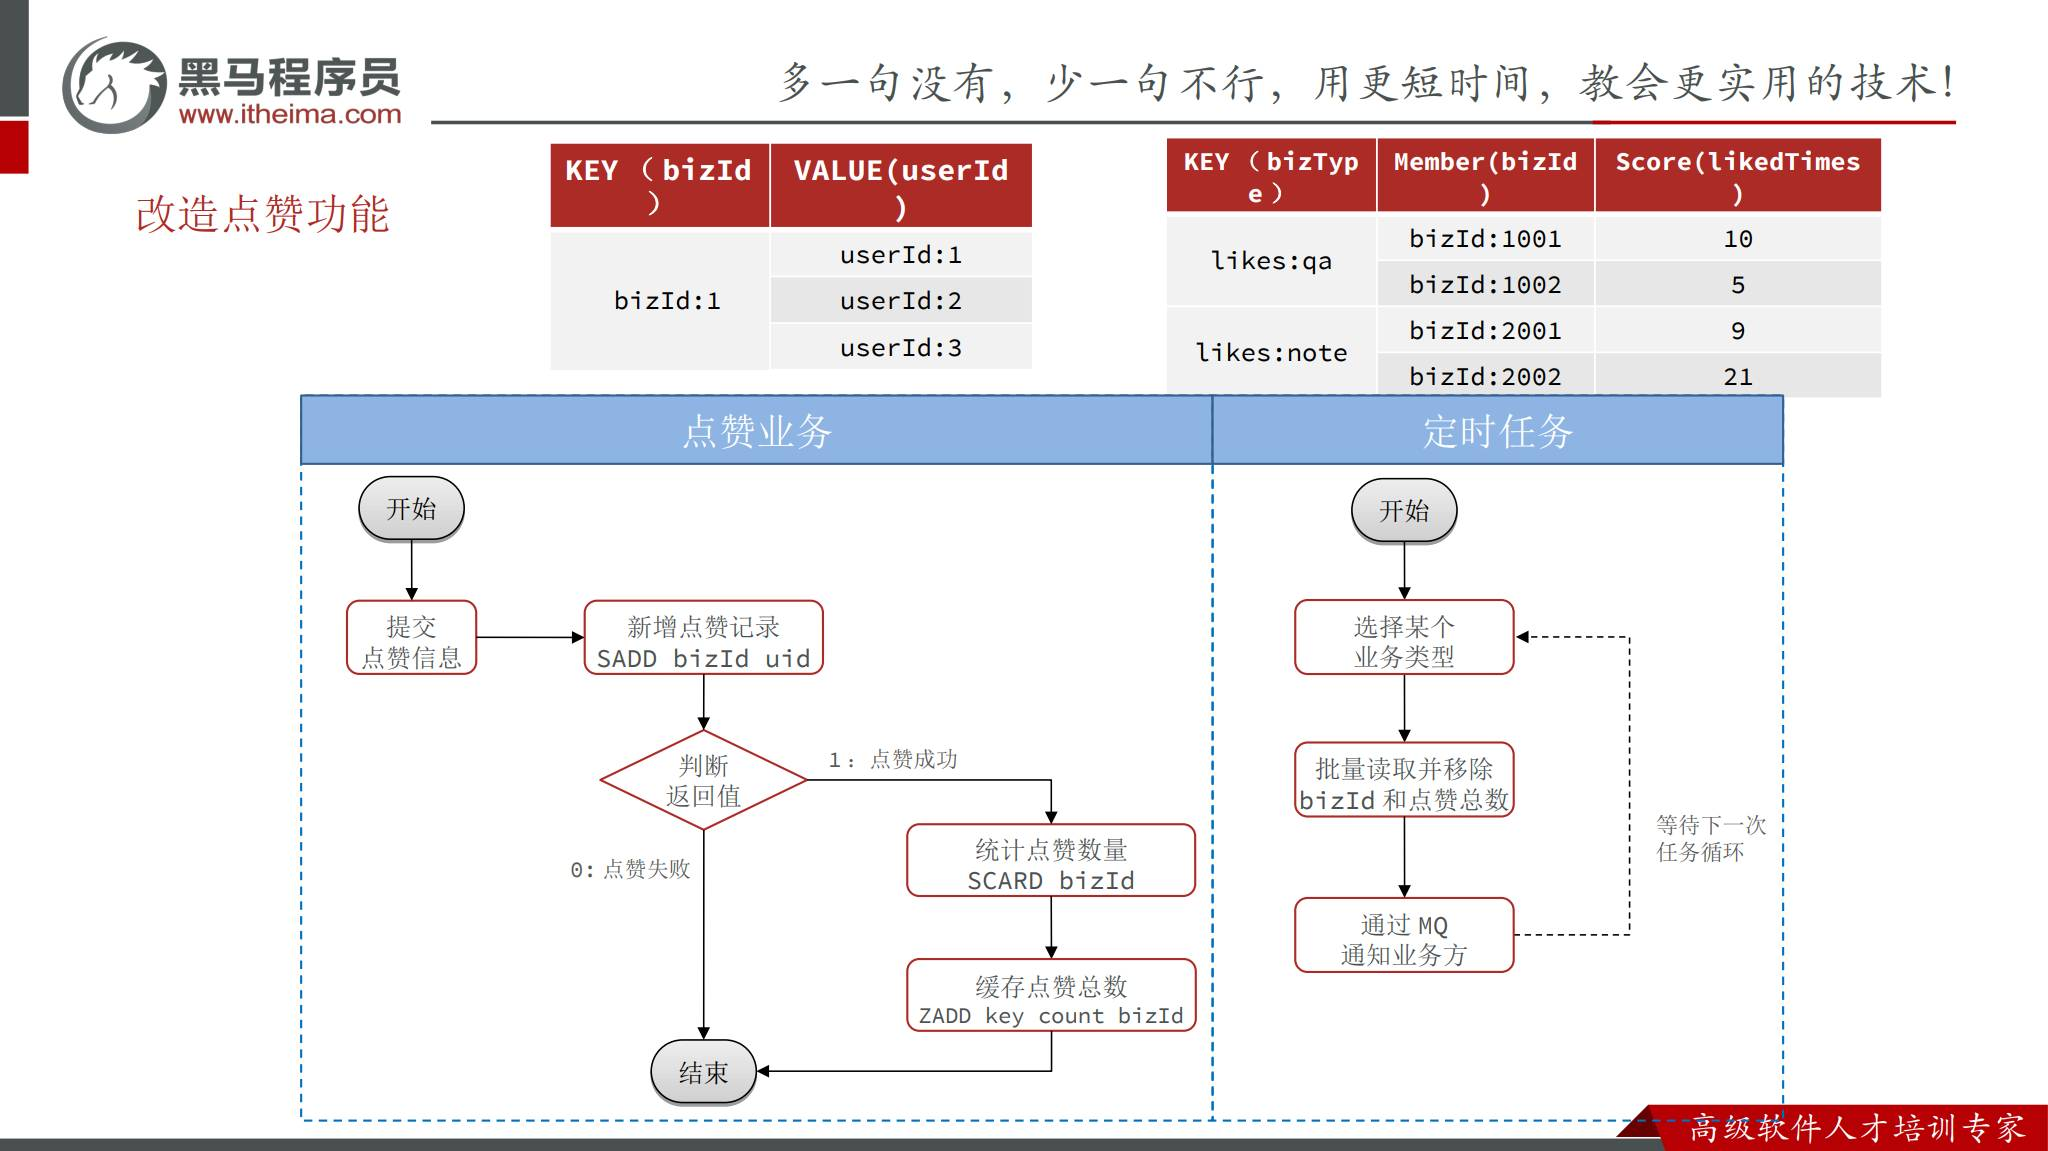

图里的“0：点赞失败”表示 SADD 没有新增成员，通常意味着已经赞过。接口可以把它视为幂等完成，无需对用户报操作错误。

读图时区分两条链路：**请求成功表示关系写入完成；业务表总数更新还要等待定时任务和消息消费。** 图中的“读取并移除”同 MQ 发送之间仍有故障窗口，后文会补充恢复思路。


## Redis 版点赞与取消实现

PPT 第 24–27 页要求改造写接口。核心规则保持不变，只把关系操作和计数放到 Redis。

**整理示例**，使用全局唯一 bizId 的课程契约，键前缀是示例值：

```java
void setLikeState(LikeForm form) {
    Long uid = requireCurrentUser();
    String type = validateAndNormalizeType(form.getBizType());
    String recordKey = "likes:record:" + form.getBizId();
    String pendingKey = "likes:" + type;

    Long changed = form.getLiked()
        ? redis.opsForSet().add(recordKey, uid.toString())
        : redis.opsForSet().remove(recordKey, uid.toString());
    if (changed == null) {
        throw new IllegalStateException("未取得关系操作结果");
    }
    if (changed == 0L) {
        return;
    }
    Long total = redis.opsForSet().size(recordKey);
    if (total == null) {
        throw new IllegalStateException("未取得点赞总数");
    }
    redis.opsForZSet().add(pendingKey, form.getBizId().toString(), total);
}
```

实际 RedisTemplate、序列化器和返回值类型以依赖版本为准。使用 StringRedisTemplate 可让数字 ID 以字符串保存，查询时也要使用相同序列化方式。

取消最后一个赞时，Redis 会删除空 Set，SCARD 仍返回 0。因此总数为 0 可以正常写入 ZSet，不能用 `total > 0` 作为是否同步的条件。

> 这是 PPT 流程的直接整理，三个独立命令不构成整体原子操作。高并发下还需要处理下面的计数快照竞争。


## 单命令原子性与多命令竞争

SADD 可以防止重复关系，但它不能保证随后 SCARD、ZADD 看到和保存同一个时点的状态。

**补充：一个旧快照覆盖新快照的时序。**

| 时刻 | 请求 A | 请求 B | 结果 |
| --- | --- | --- | --- |
| 1 | 新增关系，SCARD 读到 10 | 尚未操作 | A 持有 10 |
| 2 | 尚未 ZADD | 新增关系，SCARD 读到 11 | 真正总数为 11 |
| 3 | 尚未 ZADD | ZADD 写入 11 | 待同步为 11 |
| 4 | ZADD 写入 10 | 已结束 | 待同步退回 10 |

Set 仍正确，但任务发出的总数过时。如果后续没有新变化，这个错误可能持续存在。

另一个窗口是 SADD 成功、ZADD 前进程退出。用户重试时 SADD 返回 0，直接返回会让缺失通知继续缺失。

| 方法 | 解决范围 |
| --- | --- |
| SADD/SREM 返回值 | 单条关系操作去重 |
| Pipeline | 减少网络往返，不阻止其他请求交错 |
| Lua 脚本 | 在 Redis 内把关系修改、计数与待同步写入合为一次执行 |
| MQ 版本检查 | 处理已发送事件的乱序 |

**实践场景**：并发请求经常集中在热门回答时，用 Lua 消除旧快照覆盖；已有数据出现异常时，通过关系集合重算总数并重新同步，不能只修改页面显示数字。


## Lua 改进示例与 Redis Cluster 键槽

Lua 脚本在 Redis 内连续执行多条命令，其间其他客户端命令不能插入。它适合把“改关系、求总数、标记待同步”合在一起。

**补充 / 改进示例**，不是 PPT 已实现代码：

```lua
-- KEYS[1]：关系 Set；KEYS[2]：待同步 ZSet
-- ARGV[1]：userId；ARGV[2]：bizId；ARGV[3]：1 点赞 / 0 取消
local changed
if ARGV[3] == '1' then
    changed = redis.call('SADD', KEYS[1], ARGV[1])
else
    changed = redis.call('SREM', KEYS[1], ARGV[1])
end
if changed == 0 then
    return {0}
end
local total = redis.call('SCARD', KEYS[1])
redis.call('ZADD', KEYS[2], total, ARGV[2])
return {1, total}
```

ID 作为字符串传递，不用 Lua 数字转换 Long ID，避免大整数精度损失。脚本参数必须由服务端先验证，键类型也要保持一致。Lua 不提供出错后的自动回滚，例如第二个键类型错误可能留下前面的写入。

**Redis Cluster** 把键分配到不同槽。多键脚本要求所有 KEYS 在同一槽，课程示例的普通前缀不能保证这一点。

| 部署或键设计 | 能否执行上述多键脚本 |
| --- | --- |
| 单节点 Redis | 可以，不涉及跨槽 |
| Cluster 中任意两个键 | 可能报 CROSSSLOT |
| `likes:{qa:03}:record:1001` 与 `likes:{qa:03}:pending` | 花括号内相同，进入同一槽 |

`03` 是示例分片桶，按 bizId 稳定计算。任务需要遍历类型与桶。只用 `{qa}` 把全部问答集中到一个槽，虽然脚本能运行，但会限制水平扩展。分片、全局 ID 契约和状态查询接口必须一起设计。


## Pipeline 的原理与性能边界

PPT 第 28–31 页讨论多个 Redis 命令的网络成本。Redis 单次命令执行很快，但逐条等待结果会重复支付网络往返时间 RTT。

Pipeline 把多条命令连续发送，再批量接收结果。理想模型：

| 执行方式 | 近似耗时 |
| --- | --- |
| 逐条发送 N 条命令 | `N × RTT + N × 命令执行耗时` |
| Pipeline 批量发送 | `约 1 × RTT + N × 命令执行耗时`，另有传输与解析成本 |

如果 RTT 为 2ms，每条执行 0.05ms，20 条逐次请求约 41ms，理想批量约 3ms。数值只是说明原理，实际耗时受连接、包大小、服务负载和部署方式影响。

**Pipeline 提升的是往返效率。** 命令仍逐个执行，批次整体不具备事务原子性。关系发生变化时，批量查询也不一定得到一个一致时点的快照。

PPT 提到 MSET、HMSET 等批量命令。现代 Redis 可使用多字段 HSET 代替旧的 HMSET。批量命令能直接解决需求时优先采用；本章跨多个 Set 查询，需要 Pipeline。

每批命令数量要有上限，避免请求/响应缓冲过大、带宽和内存占用过高。先按一页业务数据分批，再根据负载测量调整，不能把整个数据库的目标一次塞进 Pipeline。


## 用 Pipeline 查询多个目标的点赞状态

Redis 版状态查询对每个 bizId 执行 SISMEMBER。如果在循环里同步调用，虽然不查数据库，仍有 N 次 Redis 往返。

**整理示例**：批量发送 SISMEMBER，把结果按提交顺序映射回 bizId。使用现代 Spring Data Redis API 展示，方法名以项目版本为准。

```java
List<Long> ids = bizIds.stream().distinct().toList();
if (ids.isEmpty()) {
    return Set.of();
}
String uid = requireCurrentUser().toString();
StringRedisSerializer serializer = new StringRedisSerializer();

List<Object> results = redis.executePipelined((RedisCallback<Object>) c -> {
    for (Long id : ids) {
        byte[] key = serializer.serialize("likes:record:" + id);
        byte[] member = serializer.serialize(uid);
        c.setCommands().sIsMember(key, member);
    }
    return null; // 回调自身返回 null，结果由 Pipeline 收集
});

if (results.size() != ids.size()) {
    throw new IllegalStateException("批量查询结果数量不匹配");
}
Set<Long> liked = new HashSet<>();
for (int i = 0; i < ids.size(); i++) {
    Object result = results.get(i);
    if (!(result instanceof Boolean)) {
        throw new IllegalStateException("未取得有效的点赞状态");
    }
    if (Boolean.TRUE.equals(result)) {
        liked.add(ids.get(i));
    }
}
return liked;
```

Pipeline 回调内入队的命令返回值不能直接当作最终结果使用。需要等批次结束后读取 `results`。没有的 Set 正常返回 false；连接或协议错误不能当作 false。

课件方案使用全局唯一业务 ID。如果使用带类型和分片桶的改进键设计，上面的构建 key 逻辑也必须改用统一 KeyBuilder，不能继续硬编码前缀。


## 定时任务批量取出待同步目标

待同步 ZSet 让任务只处理变化过的目标。PPT 第 24 页要求“批量读取并移除 bizId 和总数”，再按类型发消息。

**整理示例**选择 ZPOPMIN，批量取出并删除成员。Redis 5.0+ 支持该命令；PPT 流程没有指定必须使用这个方法名。

```redis
ZPOPMIN likes:qa 500
```

Spring 整理伪代码：

```java
void syncOneBatch(String type, int batchSize) {
    Set<ZSetOperations.TypedTuple<String>> tuples =
        redis.opsForZSet().popMin("likes:" + type, batchSize);
    if (tuples == null || tuples.isEmpty()) {
        return;
    }
    List<LikeTotal> totals = tuples.stream()
        .map(t -> new LikeTotal(
            Long.parseLong(t.getValue()), t.getScore().longValue()))
        .toList();
    publisher.publishTotals(type, totals);
}
```

`LikeTotal` 是本笔记的消息概念示例，不是附件 DTO 原文。业务字段如果是 Integer，需要检查转换上限，不能截断超大总数。

| 细节 | 意义 |
| --- | --- |
| 读与删除合为一次命令 | 避免两个任务读到同一批后互相误删 |
| 批次数有限 | 避免单次大包和长时间占用任务线程 |
| 成员取走后目标又变化 | 新 ZADD 重新入队，留到后续批次 |
| score=0 的成员 | 仍要发消息，清零业务表 |

ZPOPMIN 按点赞数从小到大取，不按更新时间。持续积压时可能延后高分成员，要检查全量处理时间。可循环取批并设置每轮最大批数，或补充按更新时间组织的待处理结构。


## 同步周期、批次与消息契约

批处理减少写入次数，但周期越长，总数越滞后。同步周期和批量数量要根据允许延迟、变化目标数量和消费者处理能力选择。

若每轮只取 B 个目标，周期 T 秒，理论处理能力约 `B/T` 个目标每秒。变化目标持续超过这个速度就会积压。单个目标变化 100 次通常合并为一个成员，估算时应使用**不同变化目标数量**。

**整理调度流程**：

```text
读取本轮配置快照
逐个遍历启用的业务类型
  在最大批次限制内取一批待同步数据
  空批次结束该类型
  发该类型的批量总数消息
本轮结束，等待下一次触发
```

调度框架可以使用项目已有 XXL-JOB 或 Spring 定时器，具体装配需核对课程代码。PPT 规定定时同步流程，本笔记不假定实际采用了哪一个注解。

| 契约变化 | 必须同步修改 |
| --- | --- |
| 单条消息变成数组 | 生产者序列化与消费者参数都要支持数组 |
| 新业务类型 | 类型白名单、路由映射、队列绑定和消费者 |
| 同步 payload 加版本 | 生产者版本生成、消费者版本比较、存储字段 |

数据库版和 Redis 版都发送总数，可以复用业务处理语义；从单条改成批量时仍需检查具体消息结构，不能只改发送循环。


## 出队、发送与失败恢复

ZPOPMIN 保证“取走一批”原子执行，但它不能把 Redis 出队与 MQ 发送绑定成一个事务。

**补充：三个故障窗口。**

| 位置 | 后果 | 所需能力 |
| --- | --- | --- |
| 出队后、发送前进程退出 | 这批通知可能丢失 | 保存处理中记录并支持恢复 |
| 发送成功但确认丢失 | 重试可能重复投递 | 消费者幂等处理 |
| 消息消费成功但 ACK 丢失 | MQ 再次投递 | 同样需要幂等 |

Publisher Confirm 表示 Broker 是否接收消息，Return 回调可发现不可路由消息。它们有助于发现发送问题，但不能恢复“出队后尚未发送就退出”的内存数据。

**改进思路**：用原子操作把 pending 数据转存到持久化的 in-flight 批次，发送得到可靠确认后再清理批次，超时任务恢复未完成批次。也可以采用 Redis Stream 或持久化事件日志组织可确认的处理流程。具体方案需要连同持久化、重复消费和版本机制一起实现。

> 发送失败后无条件 ZADD 回旧总数，会覆盖同一目标刚产生的新总数。回写恢复必须有版本判断，或者重算最新 SCARD 后标记重新同步。

数据库版也有“关系提交成功、MQ 没发出去”的窗口。可采用事务 Outbox：在同一数据库事务内写关系与待发送事件，由后台可靠投递。Outbox 解决提交与事件记录的衔接，消费者仍要处理重复和乱序。


## 总数消息的版本与乱序处理

旧消息可能因为重试或多消费者并发晚到。先收到 11，再收到旧的 10，单纯设置总数会把业务表退回 10。

**补充 / 改进示例**：为每个目标的状态变化生成单调递增的版本，消息带 `bizId`、`likedTimes`、`version`。业务表保存最后应用版本，只接收更大的版本。

```sql
-- 补充字段 liked_version 后的条件更新示例
UPDATE interaction_reply
SET liked_times = :total,
    liked_version = :version
WHERE id = :bizId
  AND liked_version < :version;
```

| 已应用版本 | 新消息 | 结果 |
| --- | --- | --- |
| 12 | version=13，total=11 | 更新为 11 |
| 13 | version=12，total=10 | 忽略旧消息 |
| 13 | version=13，total=11 | 重复事件，无变化 |
| 13 | version=14，total=10 | 接收取消后的下降 |

版本必须代表状态更新顺序，不能用总数本身代替。普通时间戳可能同毫秒重复或受时钟影响，也不天然提供严格顺序。

Redis 版应在原子关系更新过程中一起生成版本、保存总数快照，再进入可靠待发送流程。若任务取数据后才临时生成版本，较旧的快照可能被包装成较新的事件。

版本恢复也要设计：不能 Redis 重启丢失版本后从 1 开始，而数据库仍保存 1000。版本要持久化恢复或采用受控的代际规则。本节是生产一致性补充，PPT 未宣称实现这些字段。


## Redis 关系的持久化与数据恢复

优化后代码只写 Redis Set 时，关系数据就主要保存在 Redis。业务数据库里的 `likedTimes` 只是总数副本，不能还原“哪些用户赞过”。

| 数据 | 能否由其他数据重建 | 恢复依据 |
| --- | --- | --- |
| 用户与目标关系 Set | 不能从总数反推 | Redis 持久化备份或另有关系/事件存储 |
| 业务表总数 | 可以从完整关系 Set 重算 | SCARD + 重新同步 |
| pending ZSet | 可以重新标记变化目标，但要有目标清单 | 关系索引、重建扫描或事件日志 |

Redis 的 RDB 是周期快照，AOF 记录写操作。具体刷盘配置、备份和故障恢复方式决定可接受的数据丢失窗口。主从复制和故障转移本身也不保证所有已响应写入永不丢失。

**反例**：给关系 Set 随意设置 30 分钟过期。过期后用户仍看到业务表有 20 个赞，但 Redis 认为没人赞过，重复点赞就可能重新计数。

**实践场景**：冷启动从数据库版切换时，先把已有关系加载到新 Set，验证总数再切换读写；恢复后对关系集合和业务表计数做核对，将不同步目标重新入队。

若选择仅 Redis 保存关系，需要配置持久化和恢复措施；若要求更强的数据保障，可以让关系或操作事件异步落入持久化存储。不能在没有读到源码的情况下认为课程已经同时实现了双写。


## Nacos 作业：动态配置业务参数

作业正文要求把“业务类型、定时任务批处理数量、Redis 的 key 前缀”放到 Nacos。Nacos 是配置中心，服务可以在运行时读取配置变更。

**作业实现示例**，键名和默认值由本笔记设计：

```yaml
likes:
  biz-types: [qa, note]
  batch-size: 500
  key-prefix: 'likes:v1'
```

示例绑定方式，实际依赖版本需支持对应配置刷新：

```java
@Component
@RefreshScope
@ConfigurationProperties(prefix = "likes")
@Validated
@Data
public class LikeProperties {
    @NotEmpty
    private List<String> bizTypes;
    @Min(1) @Max(2000)
    private int batchSize = 500;
    @NotBlank
    private String keyPrefix = "likes:v1";
}
```

`@ConfigurationProperties` 把配置绑定到对象，`@RefreshScope` 让兼容的 Spring Cloud 刷新机制重建受管理的对象。仅加注解不足以完成刷新，还要配置实际 Nacos Data ID、Group、配置导入与刷新开关。

| 参数 | 谁读取 | 运行中变更的影响 |
| --- | --- | --- |
| 业务类型 | 参数校验、任务遍历、路由映射 | 新增类型要同步部署消费者，移除类型要先清空旧积压 |
| 批处理数量 | 每轮任务取批时 | 下轮可以采用新值，校验上下限 |
| key 前缀 | 统一 KeyBuilder | 决定数据位置，必须配合迁移 |

一次请求或一轮任务使用同一份配置快照，避免处理中前缀或类型忽然变化。不要把配置复制进 `static final` 常量，再期待它自动刷新。刷新失败保留最近有效配置并报告异常。


## 动态前缀与迁移边界

把前缀从 `likes:v1` 改成 `likes:v2`，不会重命名 Redis 中已有数据。直接读新前缀会让用户状态变为未点赞，旧 pending 集合也可能无人处理。

**补充：动态可获取与可安全切换是两个问题。**

| 变更 | 风险 | 处理方式 |
| --- | --- | --- |
| 批次 500 改成 300 | 吞吐下降或积压变化 | 下轮读取新值，观察积压 |
| 增加类型 | 新类型无人消费 | 先接入路由和消费者，再开放写入 |
| 移除类型 | 旧消息或待处理集合遗留 | 先停止新增，排空待处理数据 |
| 更改前缀 | 老关系和通知不可见 | 准备迁移与受控切换 |

可选迁移方式：维护窗口内停止写入并迁移；或设计旧/新键的兼容读取、增量复制与切换。双写方案需要处理失败和先后顺序，不能简单“两个 ZADD 都调用一下”就认为迁移可靠。

所有读写通过统一 KeyBuilder，传入本次配置快照。若使用 Lua 的 Cluster 同槽设计，KeyBuilder 还负责类型、桶和 hash tag。不要让写接口、查询接口、定时任务各拼一套键名。

批处理数量属于可调运行参数；前缀、分片规则和消息格式涉及数据结构变更，应有变更版本、兼容期和验证步骤。作业要求动态获取前缀，本节解释如何避免因此丢失可见数据。


## 身份、业务可见性与服务边界

点赞服务采用通用 ID，无法仅凭参数知道目标是否存在、是否隐藏、访问者是否有权操作。业务服务的权限规则和点赞服务的基本校验需要衔接。

**补充：接入规则。**

| 检查 | 实施位置 |
| --- | --- |
| 登录用户身份 | 网关认证与服务端可信用户上下文 |
| ID 合法、liked 必填、类型受支持 | 点赞接口校验 |
| 目标存在、课程权限、隐藏规则 | 业务侧入口或约定的校验机制 |
| 同一用户不重复关系 | 数据库唯一键或 Redis Set |
| 请求频率与批量上限 | 接口限流及参数约束 |

两种接入方式：业务服务先校验目标再调用通用点赞服务；或前端直接调用通用接口，服务按类型使用校验适配器/可信授权结果。后者增加业务依赖，应明确它对“独立服务”的影响。

问答中的匿名是返回身份的展示规则。匿名回答也有真实作者 ID，但查询点赞状态始终使用当前访问者，不能把回答作者误当成查询用户。

隐藏父级下的回复不能因增加点赞字段而重新出现在列表中。继续沿用第 05 章的可见性过滤，再给已允许返回的记录补齐状态。


## 课件、整理示例与实现核对项

本章把课件方案和扩展内容明确区分，落地前核对这些契约。

| 项目 | 已读材料给出的内容 | 实现时核对 |
| --- | --- | --- |
| 写接口 | `POST /likes`，bizId、bizType、liked | 网关前缀、响应包装、身份传递 |
| 状态接口 | `GET /likes/list`，bizIds，返回已点赞 ID 集合 | 全局 ID 保证、集合参数编码、批量上限 |
| 数据库表 | 第 10 页 `liked_record`，唯一键 bizId+userId | `tj_remark.sql` 附件全文未取得，不能假定与 PPT 完全一致 |
| 类型与路由 | 表单示例 qa/note，绑定键 QA/NOTE | 统一大小写映射 |
| DTO 附件 | 确认两个 Java 文件名 | 具体字段、包名、类型和注解未读取 |
| Redis 模型 | Set 关系、ZSet 待同步总数 | 前缀与序列化器以实际代码为准 |
| 定时同步 | 按类型批量读取并移除，发 MQ | 调度框架、周期、批次数与恢复流程 |
| Pipeline | 批量命令减少往返 | 依赖版本和结果解码 |
| Nacos | 作业要求动态获取类型、批量数、前缀 | Data ID、配置刷新与数据迁移 |
| Lua、版本、Outbox、恢复 | 本笔记的补充 / 改进内容 | 不代表 PPT 或课程仓库已实现 |

Set 的去重、ZSet 的合并、Pipeline 的提速、MQ 的解耦分别解决不同问题。把它们组合起来后，仍要检查多操作原子性与跨组件可靠性。


## 业务验证场景

以下是实现后的验证清单，本笔记未连接课程服务或执行这些测试。

| 场景 | 应得到的结果 |
| --- | --- |
| 首次点赞 | 关系增加 1，总数增加 1，进入待同步集合 |
| 重复点赞或网络重试 | 关系最多一条，不重复累计 |
| 已点赞取消 | 删除关系，重新同步总数 |
| 未点赞取消 | 无变化，不出现负数 |
| 最后一个赞取消 | Redis 计数和最终业务计数均为 0 |
| 同一目标多个用户并发点赞 | SCARD 等于不同用户数，待同步最终快照一致 |
| 两种业务目标 ID 相同 | 按选择的 ID 契约拒绝或正确隔离，不能互相影响 |
| 一页多条回答查状态 | 一次服务调用，Pipeline 结果与 ID 顺序对应 |
| 匿名或隐藏回答 | 身份与可见性继续符合第 05 章规则 |
| 相同消息重复消费 | 总数不重复增加 |
| 较旧快照晚到 | 启用版本方案时忽略旧事件 |
| 取走批次后任务退出 | 启用恢复方案时能找回未完成批次 |
| 发送失败后目标又变化 | 恢复旧批次不覆盖更新后的状态 |
| Redis 重启或数据恢复 | 关系、总数、版本与待同步状态可核对 |
| 修改批次配置 | 下轮使用新值，不接受 0 或超大批次 |
| 修改前缀/移除类型 | 迁移或排空后切换，老数据仍得到处理 |

性能验证关注 Redis 往返次数、任务积压目标数、最大同步延迟、消息大小和数据库更新量。不能只看单个 POST 请求变快，而忽略后台积压。


## 面试提示与章节衔接

**面试提示**：解释点赞系统时，先说明关系和总数分离。Set 用用户 ID 成员去重，SADD/SREM 返回值判断实际变化，SCARD 得到总数。按类型的 ZSet 用业务 ID 去重并覆盖总数，再定时批量同步到业务表。Pipeline 减少网络往返，不保证多命令原子性。继续追问一致性时，能指出 SCARD 与 ZADD 的竞争、出队到发 MQ 的故障窗口、总数快照乱序和 Redis 关系持久化问题，并分别给出改进手段。

| 容易混淆的概念 | 正确判断 |
| --- | --- |
| 幂等与顺序 | 重复同一目标状态可幂等，点赞/取消乱序仍要处理 |
| Set 原子命令与整条链路 | 单命令原子，多个命令组合需要额外保证 |
| ZSet 待同步集合与排行榜 | 前者取走就删除，不能当作全量榜单 |
| 总数快照与强一致 | 快照便于重复设置，异步同步仍有延迟 |
| Pipeline 与 Lua | 前者提升往返效率，后者可保证脚本内执行不被插入 |
| 动态配置与数据迁移 | 读取新前缀不会移动旧数据 |

第 05 章的问答内容与本章点赞状态现在能衔接：列表从业务表获得总数，批量从点赞服务取得当前用户状态。后续积分和排行榜可以利用相同的 MQ、批量处理和 Redis 思路，但积分发放规则、排行榜全量数据与这里的关系/待同步数据应分别建模。
